In [1]:
import pandas as pd

# 1. Load Titanic dataset
df = pd.read_csv("titanic.csv")

# 2. Inspect first 5 rows
print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [2]:
# Check how many missing values exist in each column
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Gender (Sex) and Ticket Class (Pclass).

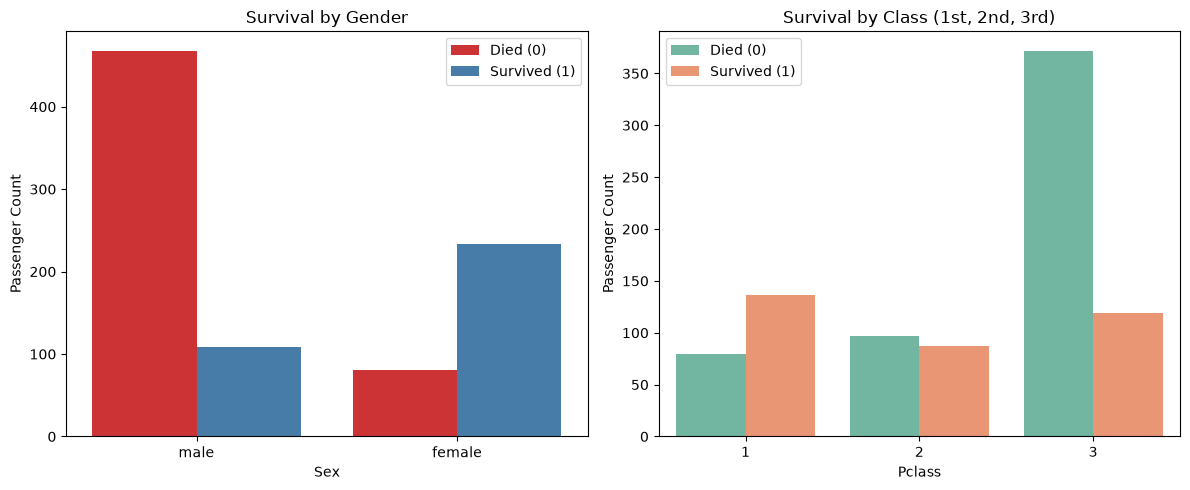

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# 1. Survival by Sex
sns.countplot(data=df, x='Sex', hue='Survived', palette='Set1', ax=axes[0])
axes[0].set_title('Survival by Gender')
axes[0].set_ylabel('Passenger Count')
axes[0].legend(['Died (0)', 'Survived (1)'])

# 2. Survival by Passenger Class (Pclass)
sns.countplot(data=df, x='Pclass', hue='Survived', palette='Set2', ax=axes[1])
axes[1].set_title('Survival by Class (1st, 2nd, 3rd)')
axes[1].set_ylabel('Passenger Count')
axes[1].legend(['Died (0)', 'Survived (1)'])

plt.tight_layout()
plt.show()

Age and Fare (continuous numbers) and Embarked (port).

C:\Users\yzd\AppData\Local\Temp\ipykernel_3564\3103008228.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Survived', y='Fare', palette='Set2', ax=axes[1])
C:\Users\yzd\AppData\Local\Temp\ipykernel_3564\3103008228.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[1].set_xticklabels(['Died (0)', 'Survived (1)'])


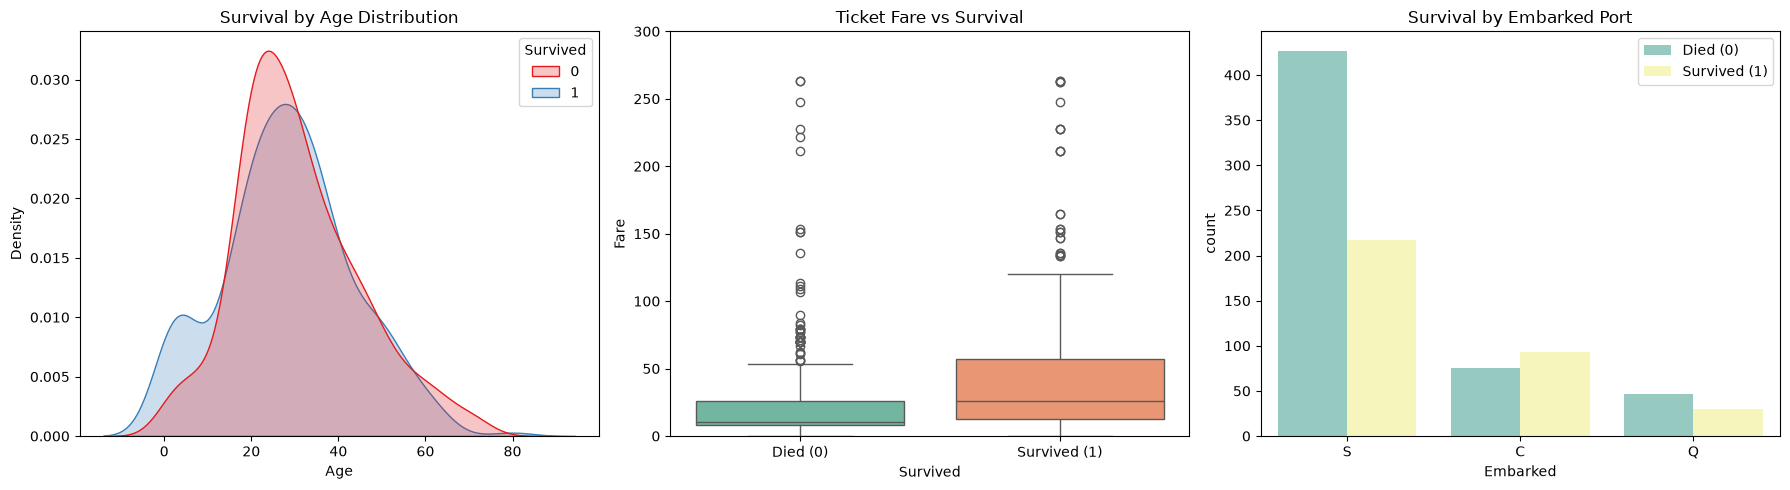

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Age Distribution vs Survival (KDE / Density curve)
sns.kdeplot(data=df, x='Age', hue='Survived', common_norm=False, fill=True, palette='Set1', ax=axes[0])
axes[0].set_title('Survival by Age Distribution')
axes[0].set_xlabel('Age')

# 2. Fare Distribution vs Survival (Boxplot - shows outliers!)
sns.boxplot(data=df, x='Survived', y='Fare', palette='Set2', ax=axes[1])
axes[1].set_title('Ticket Fare vs Survival')
axes[1].set_xticklabels(['Died (0)', 'Survived (1)'])
axes[1].set_ylim(0, 300) # zoom in up to 300 to see clearly past extreme outliers

# 3. Port of Embarkation (C = Cherbourg, Q = Queenstown, S = Southampton)
sns.countplot(data=df, x='Embarked', hue='Survived', palette='Set3', ax=axes[2])
axes[2].set_title('Survival by Embarked Port')
axes[2].legend(['Died (0)', 'Survived (1)'])

plt.tight_layout()
plt.show()

**Feature Selection & Data Cleaning (Handling Missing Values)**

In [5]:
# 1. Select relevant features and target
X = df[['Pclass', 'Sex', 'Age', 'Fare']].copy()
y = df['Survived']

# 2. Fill missing Age values with the median age (~28 years)
median_age = X['Age'].median()
X['Age'] = X['Age'].fillna(median_age)

# 3. Convert Sex to numeric: male = 1, female = 0
X['Sex'] = X['Sex'].map({'male': 1, 'female': 0})

# 4. Verify no NaN values remain
print("Missing values in X:\n", X.isnull().sum())
print("\nCleaned Features:")
X.head()

Missing values in X:
 Pclass    0
Sex       0
Age       0
Fare      0
dtype: int64

Cleaned Features:


,Pclass,Sex,Age,Fare
0,3,1,22.0,7.2500
1,1,0,38.0,71.2833
2,3,0,26.0,7.9250
3,1,0,35.0,53.1000
4,3,1,35.0,8.0500


**Train-Test Split and Training the Decision Tree**

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

# 1. Split data (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. Train Decision Tree with max_depth=4 to prevent overfitting
model = DecisionTreeClassifier(max_depth=4, random_state=42)
model.fit(X_train, y_train)

# 3. Check performance on both Train and Test sets
train_acc = model.score(X_train, y_train) * 100
test_acc = model.score(X_test, y_test) * 100

print(f"Training Accuracy: {train_acc:.2f}%")
print(f"Test Accuracy:     {test_acc:.2f}%")

Training Accuracy: 83.85%
Test Accuracy:     79.89%


**Visualizing the Titanic Decision Tree!**

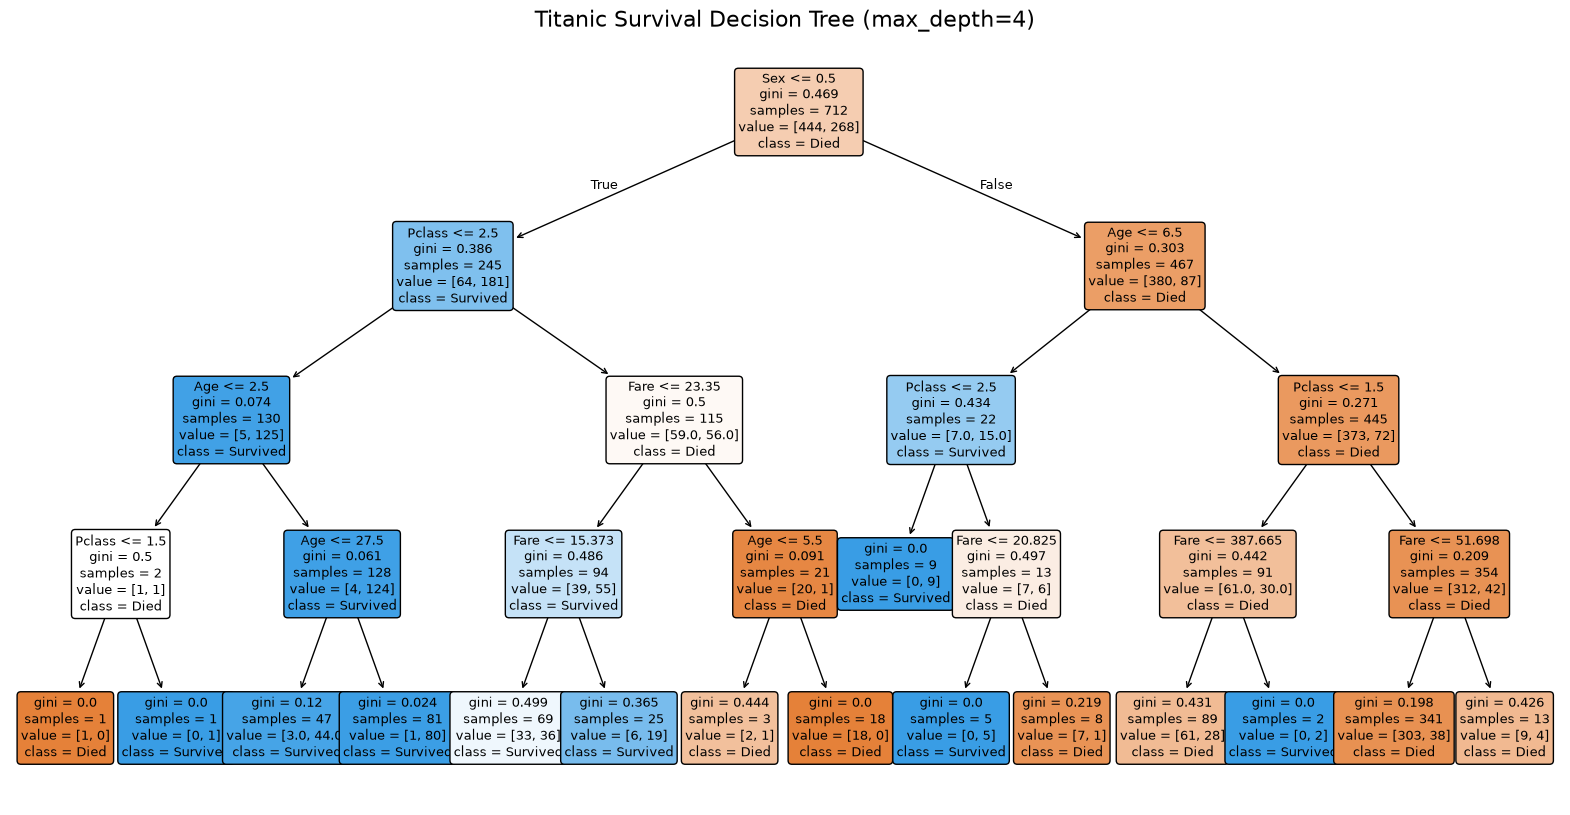

In [7]:
from sklearn import tree

plt.figure(figsize=(20, 10))
tree.plot_tree(
    model,
    feature_names=X.columns,
    class_names=['Died', 'Survived'],
    filled=True,
    rounded=True,
    fontsize=9
)
plt.title("Titanic Survival Decision Tree (max_depth=4)", fontsize=16)
plt.show()

**Confusion Matrix Heatmap & Classification Report**

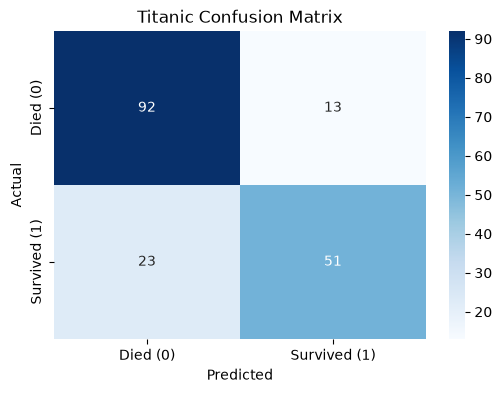

Classification Report:
              precision    recall  f1-score   support

        Died       0.80      0.88      0.84       105
    Survived       0.80      0.69      0.74        74

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179



In [8]:
from sklearn.metrics import confusion_matrix, classification_report

# 1. Predictions on test data
y_pred = model.predict(X_test)

# 2. Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Died (0)', 'Survived (1)'],
            yticklabels=['Died (0)', 'Survived (1)'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Titanic Confusion Matrix')
plt.show()

# 3. Precision, Recall, and F1-Score
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=['Died', 'Survived']))

**Interactive Survival Predictor (Test Any Custom Passenger!)**

In [9]:
def will_passenger_survive(pclass, sex, age, fare):
    """
    pclass: 1, 2, or 3
    sex: 'male' or 'female'
    age: number in years (e.g. 25)
    fare: ticket price in £ (e.g. 7.5 or 50)
    """
    sex_num = 1 if sex.lower() == 'male' else 0
    passenger_data = pd.DataFrame([[pclass, sex_num, age, fare]], 
                                  columns=['Pclass', 'Sex', 'Age', 'Fare'])
    
    prediction = model.predict(passenger_data)[0]
    probabilities = model.predict_proba(passenger_data)[0]
    
    status = "SURVIVED 🟢" if prediction == 1 else "PERISHED 🔴"
    confidence = probabilities[prediction] * 100
    
    print(f"Passenger: [Class: {pclass}st/nd/rd | {sex} | Age: {age} | Fare: £{fare}]")
    print(f"Result:    {status} (Confidence: {confidence:.1f}%)\n")
    return prediction

# Test 1: Like Rose (1st Class, Female, 20 years old, high fare £80)
will_passenger_survive(pclass=1, sex='female', age=20, fare=80)

# Test 2: Like Jack (3rd Class, Male, 20 years old, low fare £7.5)
will_passenger_survive(pclass=3, sex='male', age=20, fare=7.5)

# Test 3: Young child in 3rd class (3rd Class, Male, 4 years old, fare £15)
will_passenger_survive(pclass=3, sex='male', age=4, fare=15)

Passenger: [Class: 1st/nd/rd | female | Age: 20 | Fare: £80]
Result:    SURVIVED 🟢 (Confidence: 93.6%)

Passenger: [Class: 3st/nd/rd | male | Age: 20 | Fare: £7.5]
Result:    PERISHED 🔴 (Confidence: 88.9%)

Passenger: [Class: 3st/nd/rd | male | Age: 4 | Fare: £15]
Result:    SURVIVED 🟢 (Confidence: 100.0%)



np.int64(1)

**Save the model**

In [10]:
import joblib

# Save the trained Titanic decision tree model
joblib.dump(model, 'titanic_decision_tree_model.pkl')
print("Model saved successfully as 'titanic_decision_tree_model.pkl'!")

Model saved successfully as 'titanic_decision_tree_model.pkl'!


**Reuse the model**

In [11]:
import joblib
import pandas as pd

# 1. Load the saved model from disk
loaded_model = joblib.load('titanic_decision_tree_model.pkl')

# 2. Define new passengers
# Features: [Pclass, Sex (1=male, 0=female), Age, Fare]
new_passengers = pd.DataFrame([
    [1, 0, 30, 100.0],  # 1st class, Female, 30 yrs, £100
    [3, 1, 28, 8.05],   # 3rd class, Male, 28 yrs, £8.05
    [2, 0, 12, 30.0],   # 2nd class, Female, 12 yrs, £30
], columns=['Pclass', 'Sex', 'Age', 'Fare'])

# 3. Predict survival and probabilities
predictions = loaded_model.predict(new_passengers)
probs = loaded_model.predict_proba(new_passengers)

for i, (pred, prob) in enumerate(zip(predictions, probs)):
    result = "SURVIVED 🟢" if pred == 1 else "PERISHED 🔴"
    confidence = prob[pred] * 100
    pclass = new_passengers.iloc[i]['Pclass']
    gender = "Male" if new_passengers.iloc[i]['Sex'] == 1 else "Female"
    age = new_passengers.iloc[i]['Age']
    print(f"Passenger {i+1} ({gender}, Class {pclass}, Age {age}): {result} ({confidence:.1f}% confidence)")

Passenger 1 (Female, Class 1.0, Age 30.0): SURVIVED 🟢 (98.8% confidence)
Passenger 2 (Male, Class 3.0, Age 28.0): PERISHED 🔴 (88.9% confidence)
Passenger 3 (Female, Class 2.0, Age 12.0): SURVIVED 🟢 (93.6% confidence)
